# Chapter 20: Statistical Decision Theory: Minimaxity and Admissibility

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch20/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/izupress/statistical-theory/blob/main/notebooks/ch_20.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## Risk Curves for a Binomial Proportion

We compute the exact risk functions of the three rules of Example 20.14 for $n=16$: the MLE, the Bayes rule for the uniform prior (Laplace's rule) and the minimax rule.

*Source file:* `code/ch20/c20_1_binomial_risk_curves.py`

n = 16 | minimax risk (theory) 1/(4(1+sqrt n)^2) = 0.010000
Risk of the minimax rule: min = 0.010000, max = 0.010000  (equaliser)
Maximum risks: MLE = 0.015625 | Laplace = 0.012346 | minimax = 0.010000
Minimax rule better than MLE: p in (0.203, 0.797)  (theory: 0.2, 0.8)
Bayes risks under the uniform prior: MLE = 0.010417 | Laplace = 0.009259 | minimax = 0.010000


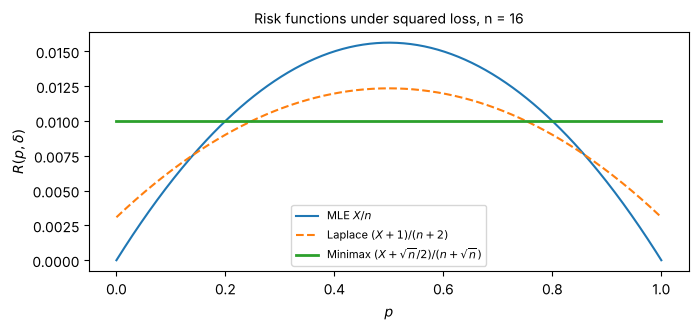

In [2]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

n = 16
p = np.linspace(0, 1, 401)
x = np.arange(n + 1)
pmf = stats.binom.pmf(x[:, None], n, p[None, :])          # (n+1) x len(p)

def risk(d):                                               # exact risk under squared loss
    return ((d[:, None] - p[None, :])**2 * pmf).sum(axis=0)

mle = x / n
a = np.sqrt(n) / 2
minimax = (x + a) / (n + 2 * a)                           # Bayes for Beta(sqrt(n)/2, sqrt(n)/2)
laplace = (x + 1) / (n + 2)                                # Bayes for Beta(1,1)
R_mle, R_mm, R_lap = risk(mle), risk(minimax), risk(laplace)

print(f"n = {n} | minimax risk (theory) 1/(4(1+sqrt n)^2) = {1/(4*(1+np.sqrt(n))**2):.6f}")
print(f"Risk of the minimax rule: min = {R_mm.min():.6f}, max = {R_mm.max():.6f}  (equaliser)")
print(f"Maximum risks: MLE = {R_mle.max():.6f} | Laplace = {R_lap.max():.6f} | minimax = {R_mm.max():.6f}")
better = p[R_mm < R_mle]
print(f"Minimax rule better than MLE: p in ({better.min():.3f}, {better.max():.3f})  (theory: 0.2, 0.8)")
print(f"Bayes risks under the uniform prior: MLE = {np.trapezoid(R_mle, p):.6f} | "
      f"Laplace = {np.trapezoid(R_lap, p):.6f} | minimax = {np.trapezoid(R_mm, p):.6f}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(p, R_mle, label=r"MLE $X/n$")
ax.plot(p, R_lap, "--", label=r"Laplace $(X+1)/(n+2)$")
ax.plot(p, R_mm, lw=2, label=r"Minimax $(X+\sqrt{n}/2)/(n+\sqrt{n})$")
ax.set_xlabel("$p$"); ax.set_ylabel(r"$R(p,\delta)$"); ax.legend(fontsize=8)
ax.set_title(f"Risk functions under squared loss, n = {n}", fontsize=10)
fig.tight_layout(); fig.savefig("karar_binom_risk.pdf")

## The Risk Set in a Two-Point Problem

$X\sim\text{Bin}(5,\theta)$, $\theta\in\{0.3,\,0.6\}$ and 0–1 loss. Every subset of $\{0,\dots,5\}$ defines a non-randomised rule of the form “decide $\theta_1$ if $X$ is in this set”; each of the $2^6=64$ rules is a point $(R(\theta_0,\delta),R(\theta_1,\delta))$ in the plane. The risk set of the randomised rules is the convex hull of these points. The minimax rule is the point where the lower boundary of the hull meets the diagonal; by Theorem 20.6 it corresponds to the Bayes rule for the prior $\pi^*$ that maximises $r(\pi)=\sum_x\min\{\pi f_0(x),(1-\pi)f_1(x)\}$.

*Source file:* `code/ch20/c20_2_two_point_risk_set.py`

Number of non-randomised rules: 64
Smallest max. risk among non-randomised rules = 0.3174
Least favourable prior pi* = 0.4274 | minimax risk = max_pi r(pi) = 0.2515
LR threshold = 0.7464, boundary x = [2], randomisation probability gamma = 0.2863
Minimax rule: R0 = 0.2515, R1 = 0.2515 (equal error probabilities)


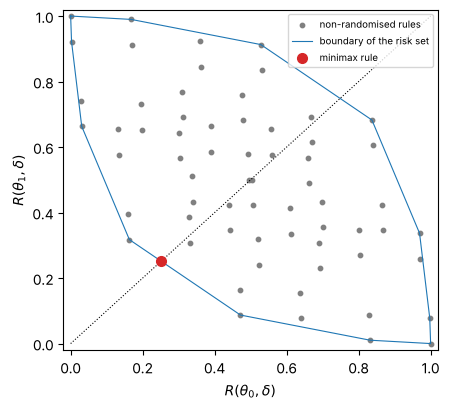

In [3]:
import itertools
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

n, t0, t1 = 5, 0.3, 0.6
x = np.arange(n + 1)
f0, f1 = stats.binom.pmf(x, n, t0), stats.binom.pmf(x, n, t1)

# 0-1 loss: R0 = P_t0(decide theta1), R1 = P_t1(decide theta0). 2^6 non-randomised rules.
points = []
for A in itertools.product([0, 1], repeat=n + 1):          # A[x]=1: decide theta1
    A = np.array(A)
    points.append((f0[A == 1].sum(), f1[A == 0].sum()))
points = np.array(points)

pi = np.linspace(0, 1, 100_001)                            # pi = P(theta = theta0)
bayes = np.minimum(pi[:, None] * f0, (1 - pi[:, None]) * f1).sum(axis=1)
j = bayes.argmax()
print(f"Number of non-randomised rules: {len(points)}")
print(f"Smallest max. risk among non-randomised rules = {points.max(axis=1).min():.4f}")
print(f"Least favourable prior pi* = {pi[j]:.4f} | minimax risk = max_pi r(pi) = {bayes[j]:.4f}")

# Bayes rule at pi*: theta1 if LR = f1/f0 > pi*/(1-pi*); randomise at equality
lr = f1 / f0; thr = pi[j] / (1 - pi[j])
strict = lr > thr + 1e-9; bnd = np.isclose(lr, thr, atol=1e-3)
gamma = (f1[~strict].sum() - f0[strict].sum()) / (f0[bnd].sum() + f1[bnd].sum())
R0 = f0[strict].sum() + gamma * f0[bnd].sum()
R1 = f1[~strict & ~bnd].sum() + (1 - gamma) * f1[bnd].sum()
print(f"LR threshold = {thr:.4f}, boundary x = {x[bnd]}, randomisation probability gamma = {gamma:.4f}")
print(f"Minimax rule: R0 = {R0:.4f}, R1 = {R1:.4f} (equal error probabilities)")

fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.scatter(*points.T, s=10, color="gray", label="non-randomised rules")
from scipy.spatial import ConvexHull
h = ConvexHull(points); v = np.append(h.vertices, h.vertices[0])
ax.plot(*points[v].T, lw=0.8, color="C0", label="boundary of the risk set")
ax.plot([0, 1], [0, 1], ":", color="k", lw=0.8)
ax.plot(R0, R1, "o", color="C3", ms=7, label="minimax rule")
ax.set_xlabel(r"$R(\theta_0,\delta)$"); ax.set_ylabel(r"$R(\theta_1,\delta)$")
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.legend(fontsize=7, loc="upper right")
fig.tight_layout(); fig.savefig("karar_risk_kumesi.pdf")